##  2 – Tự tính lan truyền tiến

In [1]:
# -*- coding: utf-8 -*-



import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f"z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]}"
      f" + ({b}) = {z:.2f}")
print(f"a = sigmoid(z) = {sigmoid(z):.4f}")
print()

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
# Trọng sốtựđặt đểmạng tính đúng phép XOR
W1 = np.array([[1.0, 1.0],# cột 1: trọng sốvào nơ-ron ẩn h1
              [1.0, 1.0]])# cột 2: trọng sốvào nơ-ron ẩn h2
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print("x1x2h1h2y")
for x in X:
    h = relu(x @ W1 + b1)# lớp ẩn
    y = h @ W2 + b2# lớp ra
    print(f"{x[0]:.0f}{x[1]:.0f}{h[0]:.0f}{h[1]:.0f}"
         f"{y:.0f}")
print()

# Cảbốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)


Mot no-ron:
z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
a = sigmoid(z) = 0.8581

Mang giai XOR:
x1x2h1h2y
00000
01101
10101
11210

Tinh ca bang mot lan: [0. 1. 1. 0.]


##  3 – Một nơ-ron và một lớp ẩn trên XOR

In [2]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("data/xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}")
print()

# Dữliệu nhỏnên dùng solver="lbfgs", học nhanh và ổn định hơn
print("So no-ron anso tham sotap hoctap kiem tra")
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs",
                      max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    # coefs_ là danh sách ma trận trọng số, intercepts_ là hệsốchặn
    so_ts = sum(w.size for w in mlp.coefs_)
    so_ts += sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"{so:2d}{so_ts:3d}{a_hoc:.4f}"
         f"{a_kt:.4f}")


Hoi quy logistic: 0.4500

So no-ron anso tham sotap hoctap kiem tra
 1  50.65330.6900
 2  90.65330.6900
 4 170.90330.9300
 8 330.91670.9100


##  4 – Độ lớn mạng và điều chuẩn

- Dùng Adam và dừng sớm ở phần này để giảm thời gian chạy so với LBFGS trong PDF

In [3]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def mang(lop_an, alpha):
    return make_pipeline(
       StandardScaler(),
       MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha,
                    solver="adam", early_stopping=True, n_iter_no_change=15, max_iter=400, random_state=0),
    )


print("Ba mangtap hoctap kiem tra")
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                         ("(100, 100), 1e-5", (100, 100), 1e-5),
                         ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f"{ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
         f"{accuracy_score(y_te, m.predict(X_te)):.4f}")
print()

# Chọn alpha bằng kiểm định chéo, chỉtrên tập học
print("alphakiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha),
                               X_tr, y_tr, cv=5).mean()
    print(f"{alpha:<8}{diem[alpha]:.4f}")
a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra "
      f"{accuracy_score(y_te, m.predict(X_te)):.4f}")


Ba mangtap hoctap kiem tra
(2,), alpha 1e-4   0.49780.5067
(100, 100), 1e-5   0.83110.8133
(100, 100), 1.0    0.82220.8000

alphakiem dinh cheo
1e-05   0.8133
0.001   0.8133
0.1     0.8089
1.0     0.8133
3.0     0.8222
10.0    0.8222
alpha tot nhat = 3.0, tap kiem tra 0.8000


##  5 – Mạng nơ-ron khi quên chuẩn hoá

In [4]:
# -*- coding: utf-8 -*-
"""Bước 4: mạng nơ-ron khi quên chuẩn hoá."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                  random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                 random_state=0),
).fit(X_tr, y_tr)

print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Khong chuan hoa: "
      f"{accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa: "
      f"{accuracy_score(y_te, chuan.predict(X_te)):.4f}")
print()

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))


Doan bua ca lop qua : 0.6000
Khong chuan hoa: 0.4000
Co chuan hoa: 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


##  6 – Nhận dạng chữ số viết tay

In [5]:
# -*- coding: utf-8 -*-
"""Bước 5: nhận dạng chữsốviết tay bằng MLP."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mang = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                 random_state=0),
).fit(X_tr, y_tr)
mlp = mang[-1]

print("Kich thuoc cac ma tran trong so:",
      [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_)
so_ts += sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f},"
      f" vong cuoi: {mm[-1]:.4f}")
print()

du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()

# Dừng sớm: giữriêng 10% tập học đểtheo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                 early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy",
      f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}")
print()

# So với các mô hình đã học, cùng tập học và tập kiểm tra
khac = {
    "Logistic co chuan hoa": make_pipeline(
       StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")


Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
anh   6: that la 9, doan la 3
anh  61: that la 5, doan la 7
anh  77: that la 2, doan la 1
anh  85: that la 9, doan la 7
anh 276: that la 8, doan la 2
anh 428: that la 7, doan la 9
anh 443: that la 4, doan la 7

Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


## Bài tập

### Bài tập 1 – Tự dự đoán bằng trọng số đã học

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv('data/xor.csv')
X, y = df[['x1', 'x2']], df['nhan']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
mlp = MLPClassifier(hidden_layer_sizes=(8,), solver='lbfgs', max_iter=5000, random_state=0)
mlp.fit(X_tr, y_tr)
x5 = X_te.iloc[:5].to_numpy()
W1, W2 = mlp.coefs_
b1, b2 = mlp.intercepts_
# Hàm kích hoạt ẩn là ReLU, đầu ra nhị phân dùng sigmoid
h = np.maximum(0, x5 @ W1 + b1)
z = h @ W2 + b2
xac_suat_tu_tinh = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
xac_suat_thu_vien = mlp.predict_proba(x5)[:, 1]
print('Tự tính:', np.round(xac_suat_tu_tinh.ravel(), 8))
print('Thư viện:', np.round(xac_suat_thu_vien, 8))
print('Sai lệch lớn nhất:', np.max(np.abs(xac_suat_tu_tinh.ravel() - xac_suat_thu_vien)))
assert np.allclose(xac_suat_tu_tinh.ravel(), xac_suat_thu_vien)


Tự tính: [0.01755799 0.99943483 0.79433106 0.13440089 0.95780572]
Thư viện: [0.01755799 0.99943483 0.79433106 0.13440089 0.95780572]
Sai lệch lớn nhất: 2.7755575615628914e-17


C:\Users\Khương Tử\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MLPClassifier was fitted with feature names
  warnings.warn(


**Nhận xét**

- Kết quả tự tính khớp với thư viện vì cả hai dùng cùng trọng số, hệ số chặn, ReLU và sigmoid.

### Bài tập 2 – Một mạng XOR khác

In [7]:
import numpy as np
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
h1 = np.maximum(0, X[:, 0] - X[:, 1])
h2 = np.maximum(0, X[:, 1] - X[:, 0])
y = h1 + h2
for x, a, b, kq in zip(X, h1, h2, y):
    print(f'({int(x[0])}, {int(x[1])}) | h1 = {int(a)}, h2 = {int(b)} | y = {int(kq)}')
assert np.array_equal(y, [0, 1, 1, 0])


(0, 0) | h1 = 0, h2 = 0 | y = 0
(0, 1) | h1 = 0, h2 = 1 | y = 1
(1, 0) | h1 = 1, h2 = 0 | y = 1
(1, 1) | h1 = 0, h2 = 0 | y = 0


**Nhận xét**

- Hai đầu vào giống nhau thì cả hai nơ-ron ẩn bằng 0.
- Khi hai đầu vào khác nhau, một nơ-ron bằng 1 nên đầu ra bằng 1, đúng phép XOR.

### Bài tập 3 – So sánh các hàm kích hoạt

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv('data/hai_vang_trang.csv')
X, y = df[['x1', 'x2']], df['nhan']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
ket_qua = {}
for activation in ['logistic', 'tanh', 'relu']:
    model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(100, 100),
        activation=activation, alpha=1.0, solver='adam', early_stopping=True, n_iter_no_change=15, max_iter=400, random_state=0))
    model.fit(X_tr, y_tr)
    train_acc = accuracy_score(y_tr, model.predict(X_tr))
    test_acc = accuracy_score(y_te, model.predict(X_te))
    ket_qua[activation] = test_acc
    print(activation, '| train =', round(train_acc, 4), '| test =', round(test_acc, 4))
print('Hàm có Accuracy tập kiểm tra cao nhất:', max(ket_qua, key=ket_qua.get))


logistic | train = 0.4978 | test = 0.5067
tanh | train = 0.8311 | test = 0.8267
relu | train = 0.8222 | test = 0.8
Hàm có Accuracy tập kiểm tra cao nhất: tanh


**Nhận xét**

- Mỗi hàm kích hoạt xử lý tín hiệu khác nhau nên kết quả có thể khác nhau.
- Em chọn hàm tốt nhất dựa trên Accuracy tập kiểm tra của lần thử này.

### Bài tập 4 – Tốc độ học trên chữ số viết tay

C:\Users\Khương Tử\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:780: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Learning rate: 0.0001 | vòng: 300 | loss cuối: 0.08295 | Accuracy: 0.9778
Learning rate: 0.001 | vòng: 144 | loss cuối: 0.00521 | Accuracy: 0.9844
Learning rate: 0.01 | vòng: 38 | loss cuối: 0.00108 | Accuracy: 0.9778
Learning rate: 0.1 | vòng: 30 | loss cuối: 0.11674 | Accuracy: 0.9622


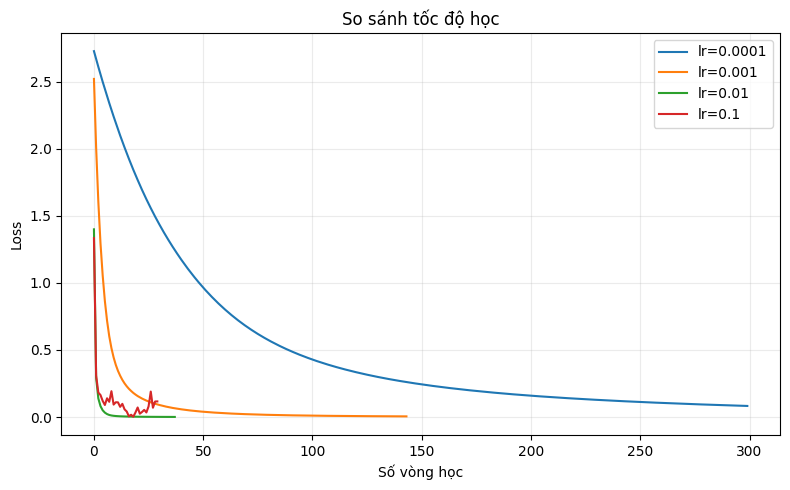

Đã lưu toc_do_hoc.png


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
scaler = StandardScaler().fit(X_tr)
X_tr = scaler.transform(X_tr)
X_te = scaler.transform(X_te)
plt.figure(figsize=(8, 5))
for lr in [0.0001, 0.001, 0.01, 0.1]:
    model = MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=lr,
                          max_iter=300, random_state=0)
    model.fit(X_tr, y_tr)
    print('Learning rate:', lr, '| vòng:', model.n_iter_,
          '| loss cuối:', round(model.loss_curve_[-1], 5),
          '| Accuracy:', round(accuracy_score(y_te, model.predict(X_te)), 4))
    plt.plot(model.loss_curve_, label=f'lr={lr}')
plt.xlabel('Số vòng học')
plt.ylabel('Loss')
plt.title('So sánh tốc độ học')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('toc_do_hoc.png', dpi=150)
plt.show()
print('Đã lưu toc_do_hoc.png')


**Nhận xét**

- Tốc độ học quá nhỏ khiến loss giảm chậm.
- Tốc độ học quá lớn có thể làm loss dao động hoặc mô hình học không ổn định.

### Bài tập 5 – Dò lưới mạng nơ-ron

In [10]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
pipe = make_pipeline(StandardScaler(), MLPClassifier(max_iter=200, early_stopping=True, n_iter_no_change=12, random_state=0))
luoi = {'mlpclassifier__hidden_layer_sizes': [(10,), (50,), (100,), (50, 50)],
        'mlpclassifier__alpha': [0.0001, 0.01, 1.0]}
search = GridSearchCV(pipe, luoi, cv=3, scoring='accuracy', n_jobs=1)
search.fit(X_tr, y_tr)
mlp_acc = accuracy_score(y_te, search.predict(X_te))
svm = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10)).fit(X_tr, y_tr)
svm_acc = accuracy_score(y_te, svm.predict(X_te))
print('Thông số tốt nhất:', search.best_params_)
print('Accuracy CV:', round(search.best_score_, 4))
print('MLP Accuracy test:', round(mlp_acc, 4))
print('SVM Accuracy test:', round(svm_acc, 4))
print('MLP vượt SVM:', mlp_acc > svm_acc)


Thông số tốt nhất: {'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (100,)}
Accuracy CV: 0.9443
MLP Accuracy test: 0.9578
SVM Accuracy test: 0.98
MLP vượt SVM: False


**Nhận xét**

- GridSearchCV chọn cấu hình bằng kiểm định chéo trên tập học.
- Sau khi chọn xong mới so MLP và SVM trên tập kiểm tra.

### Bài tập 6 – Mạng nơ-ron cho hồi quy

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('data/gia_nha.csv')
X, y = df[['dien_tich']], df['gia']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)
mlp = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(20,),
                    max_iter=5000, random_state=0))
mlp.fit(X_tr, y_tr)
linear = LinearRegression().fit(X_tr, y_tr)
print('MAE MLP:', round(mean_absolute_error(y_te, mlp.predict(X_te)), 4))
print('MAE Linear Regression:', round(mean_absolute_error(y_te, linear.predict(X_te)), 4))
moi = pd.DataFrame({'dien_tich': [250.0]})
print('250 m² - MLP:', round(float(mlp.predict(moi)[0]), 4), 'tỷ')
print('250 m² - Linear:', round(float(linear.predict(moi)[0]), 4), 'tỷ')


MAE MLP: 0.505
MAE Linear Regression: 0.3123
250 m² - MLP: 28.6338 tỷ
250 m² - Linear: 20.0672 tỷ


**Nhận xét**

- Giá nhà 250 m² nằm ngoài khoảng diện tích của dữ liệu học.
- Mạng nơ-ron không nhất thiết ngoại suy tốt như đường thẳng; cần thận trọng khi dự đoán ngoài dữ liệu.